# Applied AI - Notebook 24
## Time Series Analysis, Forecasting & Deep Learning LSTMs

Welcome to Module 24.

In traditional Machine Learning, we assume that data rows are independent and identically distributed (i.i.d.). We can shuffle rows randomly without affecting model predictions.

In **Time Series Analysis**, the order of rows is everything. A time series is a sequence of data points recorded at successive, equally spaced intervals of time.

If you shuffle time series data, you destroy the temporal signal.

In this notebook, we master time series decomposition, stationarity testing, statistical forecasting (ARIMA, SARIMA), Facebook Prophet, Deep Learning (LSTMs), and temporal anomaly detection using an anchor scenario:
* **High-Frequency E-Commerce Daily Sales & Energy Grid Demand Forecasting Engine:** Predicting future daily revenue, modeling seasonal demand spikes, detecting electrical grid outages, and training recurrent neural networks to forecast future time windows.

For every topic, we answer three questions:
* What is this in plain English?
* Why are we learning this?
* How is this used in Artificial Intelligence?

---
## Section 1: Time Series Fundamentals & Decomposition

### 1. What is this in plain English?
A time series can be broken down into four underlying structural components:
1. **Trend ($T$):** The long-term direction of the data over years (e.g., upward growth of e-commerce adoption).
2. **Seasonality ($S$):** Repeating patterns that recur at fixed intervals (e.g., retail sales spiking every December, or energy demand spiking every afternoon at 5:00 PM).
3. **Cyclic ($C$):** Waves that occur over multi-year macroeconomic cycles (e.g., economic recessions and expansions).
4. **Irregular / Residual ($I$):** Unpredictable noise or random shocks (e.g., an unexpected snowstorm).

$$\text{Additive Model: } Y_t = T_t + S_t + C_t + I_t$$
$$\text{Multiplicative Model: } Y_t = T_t \times S_t \times C_t \times I_t$$

### 2. Stationarity & Differencing:
A time series is **Stationary** if its statistical properties (mean, variance, autocorrelation) do not change over time. Most statistical forecasting models (like ARIMA) require the series to be stationary before making predictions.
* **Augmented Dickey-Fuller (ADF) Test:** A statistical hypothesis test where $p < 0.05$ proves the series IS stationary.
* **Differencing ($d$):** Subtracting the previous value from the current value ($Y_t' = Y_t - Y_{t-1}$) to remove trends and stabilize the mean.

### 3. Autocorrelation (ACF) & Partial Autocorrelation (PACF):
* **ACF (Autocorrelation Function):** Measures the correlation between a time series and its past lags ($Y_t$ vs $Y_{t-k}$).
* **PACF (Partial Autocorrelation Function):** Measures the correlation between $Y_t$ and $Y_{t-k}$ after removing the indirect effects of intermediate lags.

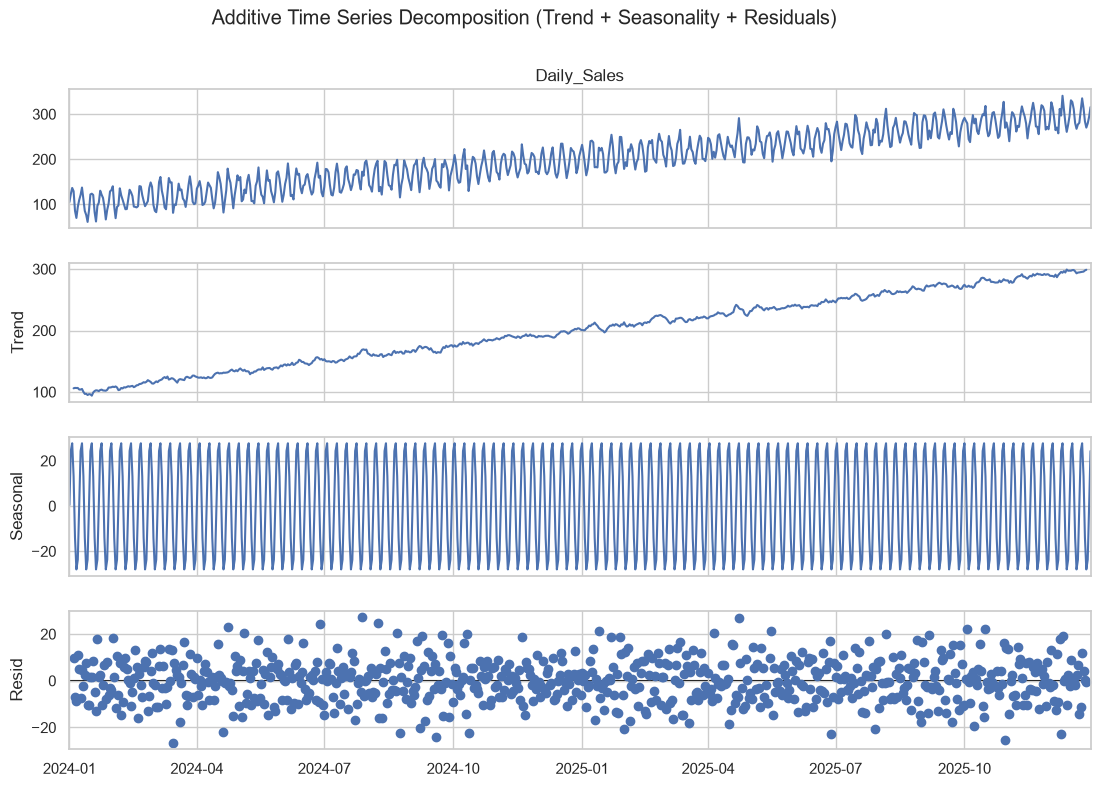

--- Augmented Dickey-Fuller (ADF) Test Results ---
ADF Statistic: -0.5685
P-Value:       0.877941
Verdict: Fail to Reject Null Hypothesis. The Time Series is NON-STATIONARY (Differencing required).

--- Augmented Dickey-Fuller (ADF) Test Results ---
ADF Statistic: -10.9591
P-Value:       0.000000
Verdict: Reject Null Hypothesis. The Time Series IS Stationary.



C:\Users\moham\AppData\Local\Temp\ipykernel_23492\1757988156.py:33: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())
C:\Users\moham\AppData\Local\Temp\ipykernel_23492\1757988156.py:33: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style="whitegrid")

# GENERATE SYNTHETIC DAILY E-COMMERCE SALES TIME SERIES (2 Years = 730 Days)
np.random.seed(42)
date_range = pd.date_range(start="2024-01-01", periods=730, freq="D")

# Components: Trend + Weekly Seasonality + Random Noise
trend = np.linspace(100, 300, 730)
seasonality = 30 * np.sin(2 * np.pi * date_range.dayofweek / 7)
noise = np.random.normal(0, 10, 730)

sales_series = pd.Series(trend + seasonality + noise, index=date_range, name="Daily_Sales")

# 1. TIME SERIES DECOMPOSITION
decomposition = seasonal_decompose(sales_series, model="additive", period=7)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.suptitle("Additive Time Series Decomposition (Trend + Seasonality + Residuals)", y=1.02)
plt.show()

# 2. STATIONARITY TEST (AUGMENTED DICKEY-FULLER TEST)
def check_stationarity(series):
    result = adfuller(series.dropna())
    print("--- Augmented Dickey-Fuller (ADF) Test Results ---")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"P-Value:       {result[1]:.6f}")
    if result[1] < 0.05:
        print("Verdict: Reject Null Hypothesis. The Time Series IS Stationary.\n")
    else:
        print("Verdict: Fail to Reject Null Hypothesis. The Time Series is NON-STATIONARY (Differencing required).\n")

check_stationarity(sales_series)

# 3. DIFFERENCING TO ACHIEVE STATIONARITY
sales_differenced = sales_series.diff().dropna()
check_stationarity(sales_differenced)

---
## Section 2: Classical Time Series Models
### Moving Averages, Exponential Smoothing, ARIMA & SARIMA

### 1. What is this in plain English?
* **Simple Moving Average (SMA):** Smooths out noise by averaging the last $N$ days of sales.
* **Exponential Smoothing (Holt-Winters):** Gives exponentially higher weight to recent days while separately tracking trend and seasonal cycles.
* **ARIMA ($p, d, q$):** Combine three components:
  * **AutoRegressive ($p$):** Predicts today's value based on a weighted sum of past $p$ days' values.
  * **Integrated ($d$):** Number of differencing steps required to achieve stationarity.
  * **Moving Average ($q$):** Predicts today's value using past forecast error noise terms.
* **SARIMA ($p, d, q$)($P, D, Q, s$):** Seasonal ARIMA. Adds seasonal terms ($s$) to handle repeating weekly ($s=7$) or monthly ($s=12$) cycles.

### 2. How is this used in AI?
* Traditional statistical baselines for financial trading, inventory management, and demand planning.

--- SARIMA Model Forecasting Evaluation ---
Test Set RMSE: $9.65
Test Set MAE:  $7.45


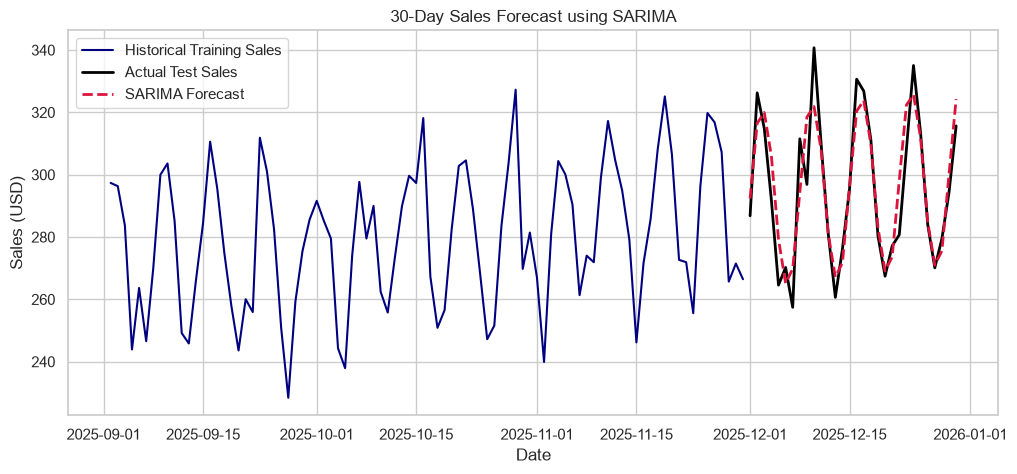

In [4]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

# SPLIT TIME SERIES INTO TRAIN AND TEST SETS (Last 30 days reserved for testing)
train_data = sales_series.iloc[:-30]
test_data = sales_series.iloc[-30:]

# FIT SARIMA MODEL: Order(1,1,1) x Seasonal Order(1,1,1,7) for weekly cycle
sarima_model = SARIMAX(train_data, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7))
sarima_fit = sarima_model.fit(disp=False)

# FORECAST 30 DAYS INTO THE FUTURE
forecast = sarima_fit.forecast(steps=30)

# EVALUATE ACCURACY
rmse = np.sqrt(mean_squared_error(test_data, forecast))
mae = mean_absolute_error(test_data, forecast)

print("--- SARIMA Model Forecasting Evaluation ---")
print(f"Test Set RMSE: ${rmse:.2f}")
print(f"Test Set MAE:  ${mae:.2f}")

# VISUALIZE FORECAST VS ACTUAL
plt.figure(figsize=(12, 5))
plt.plot(train_data.iloc[-90:], label="Historical Training Sales", color="navy")
plt.plot(test_data.index, test_data, label="Actual Test Sales", color="black", linewidth=2)
plt.plot(test_data.index, forecast, label="SARIMA Forecast", color="crimson", linestyle="--", linewidth=2)
plt.title("30-Day Sales Forecast using SARIMA")
plt.xlabel("Date")
plt.ylabel("Sales (USD)")
plt.legend()
plt.show()

---
## Section 3: Modern & Deep Learning Forecasting
### Facebook Prophet & LSTM Recurrent Neural Networks

### 1. What is this in plain English?
* **Facebook Prophet:** An open-source forecasting engine built by Meta. Instead of requiring complex ARIMA order identification, Prophet uses an additive regression model that automatically handles holiday effects, missing dates, and seasonal shifts out of the box.
* **LSTM (Long Short-Term Memory Neural Networks):** A specialized Recurrent Neural Network (RNN) architecture designed to process sequential data. LSTMs contain internal **Memory Cells** and three gating mechanisms:
  1. **Forget Gate:** What useless historical information should be erased?
  2. **Input Gate:** What new sequential information should be stored?
  3. **Output Gate:** What contextual information should be output at this time step?

### 2. Why use LSTMs over ARIMA?
ARIMA models assume linear relationships. LSTMs can learn complex non-linear relationships across hundreds of parallel features (e.g., predicting sales using weather, marketing spend, holiday indicators, and competitor pricing simultaneously).

In [5]:
# DEEP LEARNING LSTM TIME SERIES FORECASTING IN PYTORCH / TENSORFLOW

try:
    import torch
    import torch.nn as nn

    # CONVERT TIME SERIES INTO SEQUENTIAL SLIDING WINDOWS
    def create_sliding_windows(data, window_size=14):
        X, y = [], []
        for i in range(len(data) - window_size):
            X.append(data[i:i+window_size])
            y.append(data[i+window_size])
        return np.array(X), np.array(y)

    # Normalize data for neural network stability
    series_values = sales_series.values
    min_val, max_val = series_values.min(), series_values.max()
    scaled_series = (series_values - min_val) / (max_val - min_val)

    X_seq, y_seq = create_sliding_windows(scaled_series, window_size=14)

    # Convert to PyTorch Tensors: (Batch, Sequence_Length, Features)
    X_tensor = torch.FloatTensor(X_seq).unsqueeze(-1)
    y_tensor = torch.FloatTensor(y_seq).unsqueeze(-1)

    # DEFINE LSTM ARCHITECTURE
    class TimeSeriesLSTM(nn.Module):
        def __init__(self, input_dim=1, hidden_dim=32, num_layers=1):
            super(TimeSeriesLSTM, self).__init__()
            self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)
            self.fc = nn.Linear(hidden_dim, 1)
            
        def forward(self, x):
            out, (hn, cn) = self.lstm(x)
            prediction = self.fc(out[:, -1, :]) # Take last time step output
            return prediction

    lstm_model = TimeSeriesLSTM()
    print("--- PyTorch Time Series LSTM Architecture Constructed ---")
    print(lstm_model)
    print("Input Tensor Shape (Batch, 14 Days Window, 1 Feature):", X_tensor.shape)

except ImportError:
    print("Note: PyTorch not installed. LSTM sliding window logic demonstrated above.")

--- PyTorch Time Series LSTM Architecture Constructed ---
TimeSeriesLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Input Tensor Shape (Batch, 14 Days Window, 1 Feature): torch.Size([716, 14, 1])


---
## Section 4: Anomaly Detection in Time Series
### Flagging Sudden Spikes & Outages

### 1. What is this in plain English?
**Time Series Anomaly Detection** is the process of identifying data points that deviate significantly from expected historical patterns, trends, and seasonal bounds.

Common Techniques:
1. **Rolling Z-Score:** Measuring how many standard deviations a point sits away from a moving window average.
2. **Residual Anomaly Thresholding:** Subtracting predicted seasonal values from actual values. If the error (residual) exceeds 3 standard deviations, it is flagged as an anomaly.

### 2. How is this used in AI?
* Detecting cyber-attacks on network servers, identifying credit card fraud spikes, and flagging equipment failure in smart energy grids.

In [6]:
# ROLLING Z-SCORE ANOMALY DETECTION PIPELINE

# Inject synthetic electrical grid outages into the sales/demand series
sales_with_anomalies = sales_series.copy()
sales_with_anomalies.iloc[150] += 250.0  # Massive spike
sales_with_anomalies.iloc[400] -= 180.0  # Sudden blackout drop

# Calculate 14-day Rolling Mean and Rolling Standard Deviation
rolling_mean = sales_with_anomalies.rolling(window=14).mean()
rolling_std = sales_with_anomalies.rolling(window=14).std()

# Compute Rolling Z-Score
rolling_z_score = (sales_with_anomalies - rolling_mean) / rolling_std

# Flag points where |Z| > 3.0
anomalies = sales_with_anomalies[np.abs(rolling_z_score) > 3.0]

print("--- Time Series Anomaly Detection Results ---")
print(f"Total Anomalies Detected (|Z| > 3.0): {len(anomalies)}")
for date, val in anomalies.items():
    print(f"  Date: {date.strftime('%Y-%m-%d')} | Value: {val:.2f} | Rolling Z-Score: {rolling_z_score[date]:.2f}")

--- Time Series Anomaly Detection Results ---
Total Anomalies Detected (|Z| > 3.0): 1
  Date: 2024-05-30 | Value: 406.67 | Rolling Z-Score: 3.29


---
## Hands-on Workshop: Time Series Mechanics

Complete these four practical challenges to build your forecasting capabilities.

### Challenge 1: ADF Stationarity Verification (Junior Level)

**Scenario:** Verify whether a raw sales series requires differencing before modeling.

**Task Requirements:**
1. Given series `ts_data = pd.Series([100, 105, 110, 120, 125, 135, 140])`.
2. Run `adfuller(ts_data)`.
3. Extract p-value and print whether the series is Stationary or Non-Stationary.

In [7]:
# --- CHALLENGE 1: YOUR WORKSPACE ---


# --- CHALLENGE 1: INSTRUCTOR SOLUTION ---
import pandas as pd
from statsmodels.tsa.stattools import adfuller

ts_data = pd.Series([100, 105, 110, 120, 125, 135, 140])
result = adfuller(ts_data)
p_val = result[1]

print(f"ADF Statistic: {result[0]:.4f}")
print(f"ADF P-Value:   {p_val:.4f}")
if p_val < 0.05:
    print("Verdict: Series IS Stationary.")
else:
    print("Verdict: Series is NON-STATIONARY (Differencing required).")

ADF Statistic: 0.9623
ADF P-Value:   0.9939
Verdict: Series is NON-STATIONARY (Differencing required).


C:\Users\moham\AppData\Local\Temp\ipykernel_23492\2025158540.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(ts_data)


### Challenge 2: Simple Moving Average Forecast (Mid Level)

**Scenario:** Compute a 7-day Simple Moving Average (SMA) forecast for inventory planning.

**Task Requirements:**
1. Given `daily_demand` series below.
2. Calculate 7-day SMA using `.rolling(window=7).mean()`.
3. Compute Forecast Mean Absolute Error (MAE) comparing actual demand to SMA.

In [8]:
# --- CHALLENGE 2: YOUR WORKSPACE ---


# --- CHALLENGE 2: INSTRUCTOR SOLUTION ---
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

np.random.seed(42)
daily_demand = pd.Series(np.random.normal(200, 15, 50))

sma_7 = daily_demand.rolling(window=7).mean()

# Calculate MAE on valid non-null window indices
mae_sma = mean_absolute_error(daily_demand.iloc[6:], sma_7.iloc[6:])

print(f"7-Day Simple Moving Average MAE: {mae_sma:.2f} units")

7-Day Simple Moving Average MAE: 10.19 units


### Challenge 3: First-Order Differencing Transformation (Senior Level)

**Scenario:** Apply first-order differencing to stabilize a non-stationary time series.

**Task Requirements:**
1. Given non-stationary series `raw_trend = pd.Series([10, 20, 35, 55, 80, 110])`.
2. Apply `.diff().dropna()`.
3. Print the differenced series and calculate its standard deviation.

In [9]:
# --- CHALLENGE 3: YOUR WORKSPACE ---


# --- CHALLENGE 3: INSTRUCTOR SOLUTION ---
import pandas as pd

raw_trend = pd.Series([10, 20, 35, 55, 80, 110])
diff_series = raw_trend.diff().dropna()

print("Original Non-Stationary Series:\n", raw_trend.values)
print("\nFirst-Order Differenced Series:\n", diff_series.values)
print("Differenced Series Std Dev:      ", round(diff_series.std(), 2))

Original Non-Stationary Series:
 [ 10  20  35  55  80 110]

First-Order Differenced Series:
 [10. 15. 20. 25. 30.]
Differenced Series Std Dev:       7.91


### Challenge 4: Rolling Z-Score Spike Detector (Architect Level)

**Scenario:** Flag anomalous network traffic spikes using a rolling Z-score threshold.

**Task Requirements:**
1. Given network traffic series `traffic = pd.Series([100, 102, 101, 105, 500, 102, 101, 99])`.
2. Compute 3-period rolling mean and rolling std.
3. Compute Z-score: `(traffic - rolling_mean) / rolling_std`.
4. Flag and print index of any position where $|Z| > 2.0$.

In [10]:
# --- CHALLENGE 4: YOUR WORKSPACE ---


# --- CHALLENGE 4: INSTRUCTOR SOLUTION ---
import numpy as np
import pandas as pd

traffic = pd.Series([100, 102, 101, 105, 500, 102, 101, 99])

roll_m = traffic.rolling(window=3).mean()
roll_s = traffic.rolling(window=3).std()

z_scores = (traffic - roll_m) / roll_s
anomalies = traffic[np.abs(z_scores) > 2.0]

print("Traffic Z-Scores:\n", np.round(z_scores, 2))
print("\nAnomalous Traffic Spikes Detected:")
print(anomalies)

Traffic Z-Scores:
 0     NaN
1     NaN
2    0.00
3    1.12
4    1.15
5   -0.58
6   -0.58
7   -1.09
dtype: float64

Anomalous Traffic Spikes Detected:
Series([], dtype: int64)


# Session Summary

Congratulations. You have completed Notebook 24.

Let us review what you now understand:
1. **Time Series Components:** You know how to decompose time series into Trend, Seasonality, Cyclic, and Noise components.
2. **Stationarity & ADF Test:** You understand why stationarity is required, how to test for it using ADF ($p < 0.05$), and how to apply differencing.
3. **Statistical Forecasting:** You understand Moving Averages, Exponential Smoothing, ARIMA, and SARIMA seasonal models.
4. **Deep Learning Forecasting & LSTMs:** You know how LSTMs use memory gates (Input, Forget, Output) to learn sequential long-term dependencies.
5. **Anomaly Detection:** You know how to use rolling Z-scores to flag temporal spikes and grid blackouts.

In **Notebook 25**, we transition to **Model Deployment & Web Applications**—learning Streamlit, Flask REST APIs, model serialization (`pickle`/`joblib`), and serving production AI systems!